<a href="https://colab.research.google.com/github/sasikumaar1006/Retinal_disease_detection/blob/main/02_neural_networks_and_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install datasets torch torchvision scikit-learn matplotlib numpy -q

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
ds = load_dataset("zacharielegault/Kermany2017-OCT")
print(ds)
train_data = ds["train"]
test_data = ds["test"]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

data/train-00000-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

data/train-00001-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  462MB            

... (28 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})
Training samples: 108309
Testing samples: 1000


In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Test/Validation transform
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class OCTDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item['image'].convert("RGB")
        label = item['label']

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# Creating strictly separated datasets and data loaders to prevent data leakage
train_dataset = OCTDataset(train_data, transform=train_transform)
test_dataset = OCTDataset(test_data, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False) # shuffle=False for testing

print(f"Train DataLoader batches: {len(train_loader)}")
print(f"Test DataLoader batches: {len(test_loader)}")

Train DataLoader batches: 3385
Test DataLoader batches: 32


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy loaded successfully for foundational neural network experimentation!")

# 1. Implement Activation Functions and their Derivatives
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500))) # Clipped for numerical stability

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    return 1.0 - np.tanh(x)**2

# 2. Build a Simple 2-Layer Perceptron / Neural Network from Scratch using NumPy
class NumPyNeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly with small values and biases to zero
        np.random.seed(42)
        self.W1 = np.random.randn(input_size, hidden_size) * 0.01
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.01
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        # Forward propagation
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = relu(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        # Softmax for multi-class output (4 classes: CNV, DME, Drusen, Normal)
        exp_scores = np.exp(self.Z2 - np.max(self.Z2, axis=1, keepdims=True))
        self.probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
        return self.probs

    def compute_loss(self, y_true, m):
        # Cross-entropy loss
        log_probs = -np.log(self.probs[range(m), y_true] + 1e-9)
        return np.sum(log_probs) / m

    def backward(self, X, y_true, learning_rate=0.01):
        m = X.shape[0]

        # Gradient for output layer
        dZ2 = self.probs.copy()
        dZ2[range(m), y_true] -= 1
        dZ2 /= m

        # Gradients for W2, b2
        dW2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        # Gradients for hidden layer
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * relu_derivative(self.Z1)

        # Gradients for W1, b1
        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        # Update weights and biases (Gradient Descent)
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

# Test the NumPy network with dummy flattened image data (e.g., 5 samples of 224x224 pixels flattened)
dummy_X = np.random.randn(5, 224 * 224 * 3)
dummy_y = np.array([0, 1, 2, 3, 1])

nn_scratch = NumPyNeuralNetwork(input_size=224*224*3, hidden_size=64, output_size=4)
# Run forward propagation first to generate neural network probabilities
nn_scratch.forward(dummy_X)
initial_loss = nn_scratch.compute_loss(dummy_y, m=5)
print(f"Initial NumPy Neural Network Cross-Entropy Loss: {initial_loss:.4f}")

NumPy loaded successfully for foundational neural network experimentation!
Initial NumPy Neural Network Cross-Entropy Loss: 1.3730


In [ ]:
import numpy as np

# 1. Extract a batch or multiple batches from your existing train_loader
print("Extracting data from existing PyTorch train_loader for NumPy network...")
X_batches = []
y_batches = []

# Let's grab e.g. 32 batches (32 * 32 = 1,024 samples) to keep it fast
num_batches_to_extract = 32
for i, (images, labels) in enumerate(train_loader):
    if i >= num_batches_to_extract:
        break
    # Tensors are shaped [Batch, 3, 224, 224]. Flatten to [Batch, 3 * 224 * 224]
    batch_flat = images.view(images.size(0), -1).numpy()
    X_batches.append(batch_flat)
    y_batches.append(labels.numpy())

# Concatenate all extracted batches into single NumPy arrays
X_train_np = np.concatenate(X_batches, axis=0)
y_train_np = np.concatenate(y_batches, axis=0)

print(f"NumPy training subset shape from loader: {X_train_np.shape}")
print(f"NumPy labels shape from loader: {y_train_np.shape}")

# 2. Do the exact same for the test_loader
test_X_batches = []
test_y_batches = []
for i, (images, labels) in enumerate(test_loader):
    # Grab all batches from test_loader (test loader has 32 batches total)
    test_X_batches.append(images.view(images.size(0), -1).numpy())
    test_y_batches.append(labels.numpy())

X_test_np = np.concatenate(test_X_batches, axis=0)
y_test_np = np.concatenate(test_y_batches, axis=0)

print(f"NumPy test set shape from loader: {X_test_np.shape}")

# 3. Instantiate and Train the NumPy Neural Network
input_dim = 224 * 224 * 3
hidden_dim = 64
output_dim = 4

numpy_nn = NumPyNeuralNetwork(input_size=input_dim, hidden_size=hidden_dim, output_size=output_dim)

epochs = 5
learning_rate = 0.05
m_samples = X_train_np.shape[0]

print("\nStarting training of NumPy Neural Network using DataLoader-extracted data...")
for epoch in range(epochs):
    # Forward pass
    probs = numpy_nn.forward(X_train_np)

    # Compute loss
    loss = numpy_nn.compute_loss(y_train_np, m_samples)

    # Backward pass & weight update
    numpy_nn.backward(X_train_np, y_train_np, learning_rate=learning_rate)

    # Calculate accuracy
    preds = np.argmax(probs, axis=1)
    acc = np.mean(preds == y_train_np)

    print(f"Epoch {epoch+1}/{epochs} -> Loss: {loss:.4f} | Accuracy: {acc * 100:.2f}%")

# 4. Evaluate on Test Dataset from test_loader
test_probs = numpy_nn.forward(X_test_np)
test_preds = np.argmax(test_probs, axis=1)
test_acc = np.mean(test_preds == y_test_np)
print(f"\nNumPy Neural Network Test Accuracy (on full test loader): {test_acc * 100:.2f}%")

Extracting data from existing PyTorch train_loader for NumPy network...
NumPy training subset shape from loader: (1024, 150528)
NumPy labels shape from loader: (1024,)
NumPy test set shape from loader: (1000, 150528)

Starting training of NumPy Neural Network using DataLoader-extracted data...
Epoch 1/5 -> Loss: 1.3289 | Accuracy: 46.00%
Epoch 2/5 -> Loss: 6.1921 | Accuracy: 34.47%
Epoch 3/5 -> Loss: 10.5579 | Accuracy: 46.48%
Epoch 4/5 -> Loss: 1.9522 | Accuracy: 13.67%
Epoch 5/5 -> Loss: 1.7202 | Accuracy: 44.04%

NumPy Neural Network Test Accuracy (on full test loader): 29.20%


In [ ]:
# CNN
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# 1. Define Regularized Custom CNN Architecture
class RegularizedCustomCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(RegularizedCustomCNN, self).__init__()

        # Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)

        # Classifier Head (224 -> 112 -> 56 -> 28; flattened: 128 * 28 * 28 = 100352)
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(256, num_classes)

        self.gradients = None

    def activations_hook(self, grad):
        self.gradients = grad

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        x = F.relu(self.bn3(self.conv3(x)))
        if x.requires_grad:
            x.register_hook(self.activations_hook)

        x = self.pool(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

    def get_activations_gradient(self):
        return self.gradients

    def get_activations(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))
        return x

custom_cnn = RegularizedCustomCNN(num_classes=4).to(device)

# 2. Setup Loss, Optimizer (with L2 Weight Decay), and Evaluation Engine
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_cnn.parameters(), lr=0.001, weight_decay=1e-4)

def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Calculate metrics
    class_names = ['CNV', 'DME', 'DRUSEN', 'NORMAL']
    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    print("Confusion Matrix:")
    print(confusion_matrix(all_labels, all_preds))

print("Custom CNN and Evaluation framework ready!")

Custom CNN and Evaluation framework ready!


In [ ]:
import seaborn as sns
def train_model(model, train_loader, criterion, optimizer, device, epochs=1):
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            # Print progress every 100 batches
            if batch_idx % 500 == 0:
                print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx}/{len(train_loader)}] | Loss: {loss.item():.4f}")

        epoch_loss = running_loss / total
        epoch_acc = correct / total
        print(f"==> Epoch {epoch+1} Finished | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc * 100:.2f}%")

# Train for 1 epoch as an initial run
train_model(custom_cnn, train_loader, criterion, optimizer, device, epochs=1)

Epoch [1/1] | Batch [0/3385] | Loss: 0.6481
Epoch [1/1] | Batch [500/3385] | Loss: 0.9210
Epoch [1/1] | Batch [1000/3385] | Loss: 0.7687
Epoch [1/1] | Batch [1500/3385] | Loss: 0.6076
Epoch [1/1] | Batch [2000/3385] | Loss: 0.7412
Epoch [1/1] | Batch [2500/3385] | Loss: 0.3165
Epoch [1/1] | Batch [3000/3385] | Loss: 0.5229
==> Epoch 1 Finished | Train Loss: 0.6650 | Train Acc: 78.63%


Evaluating Custom CNN on test set...

--- Classification Report ---
              precision    recall  f1-score   support

         CNV       0.43      0.99      0.60       250
         DME       0.62      0.25      0.36       250
      DRUSEN       0.79      0.06      0.11       250
      NORMAL       0.80      0.95      0.86       250

    accuracy                           0.56      1000
   macro avg       0.66      0.56      0.48      1000
weighted avg       0.66      0.56      0.48      1000



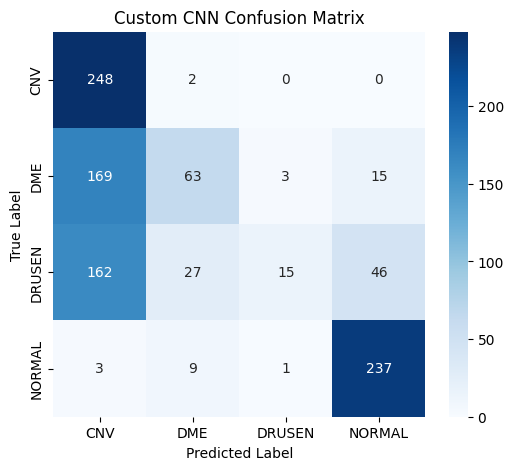

In [ ]:
import seaborn as sns
def evaluate_model(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())

    # Compute metrics
    class_names = ['CNV', 'DME', 'DRUSEN', 'NORMAL']
    print("\n--- Classification Report ---")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Custom CNN Confusion Matrix')
    plt.show()

print("Evaluating Custom CNN on test set...")
evaluate_model(custom_cnn, test_loader, device)

In [7]:
# CNN another architecture
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Dense, Dropout, Activation, Input, BatchNormalization, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, regularizers

import cv2

In [8]:
img_width, img_height = 224, 224
num_classes = 4  # CNV, DME, DRUSEN, NORMAL
l2_reg = regularizers.l2(1e-4)

model = models.Sequential([layers.Input(shape=(img_width, img_height, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', kernel_regularizer=l2_reg),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', kernel_regularizer=l2_reg),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', kernel_regularizer=l2_reg),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Classifier head (smaller dense layers + Dropout to reduce overfitting)
    layers.Flatten(),
    layers.Dense(256, kernel_regularizer=l2_reg),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',  # Use 'categorical_crossentropy' if labels are one-hot encoded
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,786,564 (98.37 MB)

 Trainable params: 25,785,604 (98.36 MB)

 Non-trainable params: 960 (3.75 KB)

In [10]:
import numpy as np

def make_tf_generator(loader):
    def _generator():
        while True:
            for images, labels in loader:
                # Convert (B, C, H, W) -> (B, H, W, C)
                x = np.transpose(images.numpy(), (0, 2, 3, 1))
                y = labels.numpy()
                yield x, y
    return _generator

history = model.fit(
    make_tf_generator(train_loader)(),
    steps_per_epoch=len(train_loader),
    epochs=2,
    validation_data=make_tf_generator(test_loader)(),
    validation_steps=len(test_loader)
)

Epoch 1/2
3385/3385 ━━━━━━━━━━━━━━━━━━━━ 1159s 342ms/step - accuracy: 0.9039 - loss: 0.6057 - val_accuracy: 0.8030 - val_loss: 0.9682
Epoch 2/2
3385/3385 ━━━━━━━━━━━━━━━━━━━━ 1166s 344ms/step - accuracy: 0.9234 - loss: 0.5471 - val_accuracy: 0.8380 - val_loss: 0.7212


In [14]:
from sklearn.metrics import classification_report, confusion_matrix
class_names = ['CNV', 'DME', 'DRUSEN', 'NORMAL']
y_true = []
y_pred = []

# Collect predictions from test_loader (channels-last for Keras)
for images, labels in test_loader:
    x = np.transpose(images.numpy(), (0, 2, 3, 1))
    probs = model.predict(x, verbose=0)
    preds = np.argmax(probs, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(preds)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

              precision    recall  f1-score   support

         CNV     0.7578    0.9760    0.8531       250
         DME     0.9945    0.7200    0.8353       250
      DRUSEN     0.7362    0.9040    0.8115       250
      NORMAL     0.9895    0.7520    0.8545       250

    accuracy                         0.8380      1000
   macro avg     0.8695    0.8380    0.8386      1000
weighted avg     0.8695    0.8380    0.8386      1000



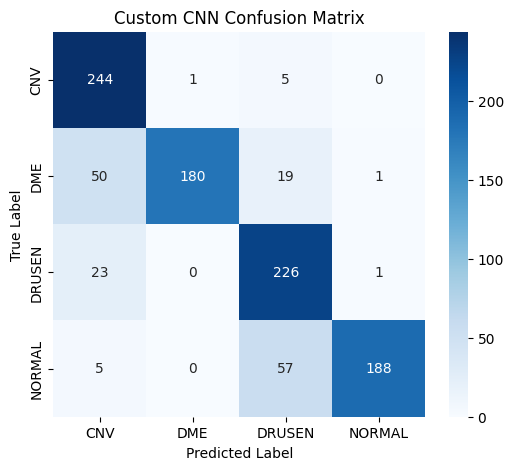

In [13]:
import seaborn as sns
cm = confusion_matrix(y_true,y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Custom CNN Confusion Matrix')
plt.show()


In [15]:
# Save the full model (architecture + weights + optimizer state)
model.save("custom_cnn_oct2017.keras")
print("Model saved to custom_cnn_oct2017.keras")

Model saved to custom_cnn_oct2017.keras


TO LOAD THE MODEL

import tensorflow as tf

loaded_cnn = tf.keras.models.load_model("custom_cnn_oct2017.keras")